[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Recover late detections with a lagged watermark

Why deliberately reread events during an incremental sync? We use the real risk worker to scan two fixed snapshots, resume from its returned watermark and deduplicate by event ID. A full reference scan reveals whether the incremental path captured a late-arriving row.

**Explicitly synthetic data.** Both snapshots describe 2026-06-01 in UTC. The initial source contains three detections; the later source adds a new detection and one whose event time is older than the first scan’s newest row. The companion injects the project’s existing `FakeRisk` client and fixed clock into the real `makeRiskFunction` factory. Paging, watermark calculation, output schemas and VGI transport remain the pinned worker’s implementation. Authentication and live Microsoft Graph behavior are outside this fixture. All identifiers and addresses are invented.

## Choose the overlap window

`SAFETY_LAG_MINUTES` is an integer from 0 to 20. The default 10-minute lag backs up the returned watermark before the next scan. The end experiment changes it to 0, then restarts the kernel and runs all cells. Source snapshots and their clocks stay fixed, isolating the cursor policy.

In [1]:
SAFETY_LAG_MINUTES = 10  # minutes; integer 0..20; experiment uses 0

In [2]:
from datetime import UTC, timedelta
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from notebook_support import finish, prose, theme

if type(SAFETY_LAG_MINUTES) is not int or not 0 <= SAFETY_LAG_MINUTES <= 20:
    raise ValueError("SAFETY_LAG_MINUTES must be an integer from 0 to 20.")
lag_unit = "minute" if SAFETY_LAG_MINUTES == 1 else "minutes"
theme()
fixture_secret_directory = TemporaryDirectory(prefix="vgi-fixture-secrets-")
connection = haybarn.connect(
    config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False}
)
assert connection.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [], (
    "Fixture must start without SQL secrets"
)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-risk/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-risk/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-risk/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-risk/notebooks/pyproject.toml.

## Attach two explicit synthetic snapshots

Both literal launchers fetch the same pinned Git revision and its frozen Bun dependencies. The final argument chooses the source snapshot. The initial clock is fixed at **12:20 UTC**, and the later clock at **12:30 UTC**, on 2026-06-01. The helper imports the original function factory/schema/catalog and supplies only its supported client and clock dependencies. The dummy secret satisfies the real function’s credential interface; it is never used for live authentication.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS initial (TYPE vgi,
    LOCATION 'bun run fixture_worker.ts Query-farm/vgi-azure-risk 74be06875655bcc88680825b159abcf778ac192c initial'
);
CREATE TEMPORARY SECRET synthetic_risk (
    TYPE azure_graph, TENANT_ID 'fixture', CLIENT_ID 'fixture', CLIENT_SECRET 'fixture'
);
ATTACH 'azure' AS later (TYPE vgi,
    LOCATION 'bun run fixture_worker.ts Query-farm/vgi-azure-risk 74be06875655bcc88680825b159abcf778ac192c later'
);

,Success


In [4]:
fixture_secrets = connection.execute("SELECT name, persistent, storage FROM duckdb_secrets() ORDER BY name").fetchall()
assert fixture_secrets == [("synthetic_risk", False, "memory")], "Only the public temporary fixture secrets may exist"

## Capture the first scan and its watermark

Materialize each worker call once. The marker row carries `_watermark_next`; its NULL business fields do not represent an event. Here the worker subtracts the selected lag from the newest detected time because that time precedes the injected clock. The next scan uses an **inclusive `>=` boundary**, so a boundary event can repeat.

In [5]:
%%sql
CREATE TABLE first_scan AS
SELECT * FROM initial.main.risk_detections(
    safety_lag := 'PT{{SAFETY_LAG_MINUTES}}M', page_size := 2
);

SELECT id, detected_date_time, _row_kind, _watermark_next
FROM first_scan ORDER BY detected_date_time NULLS LAST;

,id,detected_date_time,_row_kind,_watermark_next
0,event-a,2026-06-01T12:00:00.000Z,None,None
1,event-b,2026-06-01T12:04:00.000Z,None,None
2,event-c,2026-06-01T12:08:00.000Z,None,None
3,None,None,marker,2026-06-01T11:58:00.000Z


In [6]:
%%sql cursor_frame <<
SELECT _watermark_next AS watermark,
       CAST(_watermark_next AS TIMESTAMPTZ) AT TIME ZONE 'UTC' AS watermark_time,
       (SELECT max(CAST(detected_date_time AS TIMESTAMPTZ) AT TIME ZONE 'UTC')
        FROM first_scan WHERE _row_kind IS NULL) AS newest_detected
FROM first_scan WHERE _row_kind = 'marker';

In [7]:
display(cursor_frame)
assert len(cursor_frame) == 1, "Expected one watermark marker."
watermark = str(cursor_frame.iloc[0].watermark)

,watermark,watermark_time,newest_detected
0,2026-06-01T11:58:00.000Z,2026-06-01 11:58:00,2026-06-01 12:08:00


In [8]:
c = cursor_frame.iloc[0]
gap = (c.newest_detected - c.watermark_time).total_seconds() / 60
prose(
    f"The first scan's newest detection is **{c.newest_detected:%H:%M UTC}**. "
    f"Its returned watermark is **{c.watermark_time:%H:%M UTC}**, "
    f"an overlap of **{gap:g} {lag_unit}**. The next query passes that exact returned string as its cursor."
)

The first scan's newest detection is **12:08 UTC**. Its returned watermark is **11:58 UTC**, an overlap of **10 minutes**. The next query passes that exact returned string as its cursor.

## Resume against the later snapshot, then audit with a full scan

The small Python assignment above only transfers the returned cursor into the SQL function’s scalar argument. The incremental call and reference call both read the same fixed later snapshot. The reference is intentionally available in this small fixture to measure missed IDs; it is not a claim that frequent full scans are inexpensive in production.

In [9]:
%%sql
CREATE TABLE next_scan AS
SELECT * FROM later.main.risk_detections(
    since := '{{watermark}}',
    safety_lag := 'PT{{SAFETY_LAG_MINUTES}}M', page_size := 2
);
CREATE TABLE reference_scan AS
SELECT * FROM later.main.risk_detections(
    safety_lag := 'PT{{SAFETY_LAG_MINUTES}}M', page_size := 2
);

SELECT id, detected_date_time, _row_kind, _watermark_next
FROM next_scan ORDER BY detected_date_time NULLS LAST;

,id,detected_date_time,_row_kind,_watermark_next
0,event-a,2026-06-01T12:00:00.000Z,None,None
1,late-event,2026-06-01T12:03:00.000Z,None,None
2,event-b,2026-06-01T12:04:00.000Z,None,None
3,event-c,2026-06-01T12:08:00.000Z,None,None
4,new-event,2026-06-01T12:12:00.000Z,None,None
5,None,None,marker,2026-06-01T12:02:00.000Z


## Deduplicate overlapping reads by event ID

First inspect what simple append would produce. Then retain one row per event ID, preferring the later observation. This keeps repeated boundary/overlap rows from becoming additional events. The fixture does not change existing event attributes; production detection attributes may change, so this example makes no claim that event records are immutable.

In [10]:
%%sql
CREATE TABLE appended AS
SELECT 1 AS scan_order, id, detected_date_time, user_id
FROM first_scan WHERE _row_kind IS NULL
UNION ALL
SELECT 2, id, detected_date_time, user_id
FROM next_scan WHERE _row_kind IS NULL;

CREATE TABLE stored_events AS
SELECT id, detected_date_time, user_id
FROM appended
QUALIFY row_number() OVER (PARTITION BY id ORDER BY scan_order DESC) = 1;

CREATE TABLE reference_events AS
SELECT id, detected_date_time, user_id
FROM reference_scan WHERE _row_kind IS NULL;

SELECT id, count(*) AS observations
FROM appended GROUP BY id ORDER BY id;

,id,observations
0,event-a,2
1,event-b,2
2,event-c,2
3,late-event,1
4,new-event,1


In [11]:
%%sql audit <<
SELECT r.id, CAST(r.detected_date_time AS TIMESTAMPTZ) AT TIME ZONE 'UTC' AS event_time,
       CASE WHEN f.id IS NULL THEN 'Arrived later' ELSE 'Present initially' END AS observed_when,
       s.id IS NOT NULL AS captured
FROM reference_events r
LEFT JOIN (SELECT id FROM first_scan WHERE _row_kind IS NULL) f ON r.id = f.id
LEFT JOIN stored_events s ON r.id = s.id
ORDER BY event_time, r.id;

In [12]:
display(audit)

,id,event_time,observed_when,captured
0,event-a,2026-06-01 12:00:00,Present initially,True
1,late-event,2026-06-01 12:03:00,Arrived later,True
2,event-b,2026-06-01 12:04:00,Present initially,True
3,event-c,2026-06-01 12:08:00,Present initially,True
4,new-event,2026-06-01 12:12:00,Arrived later,True


## Locate the late arrival relative to the cursor

The horizontal axis is the detection’s event timestamp, **not its arrival time**. Marker shape distinguishes objects already present in the first snapshot from those introduced in the later snapshot. Color reports whether the incremental store contains that ID after merging both scans.

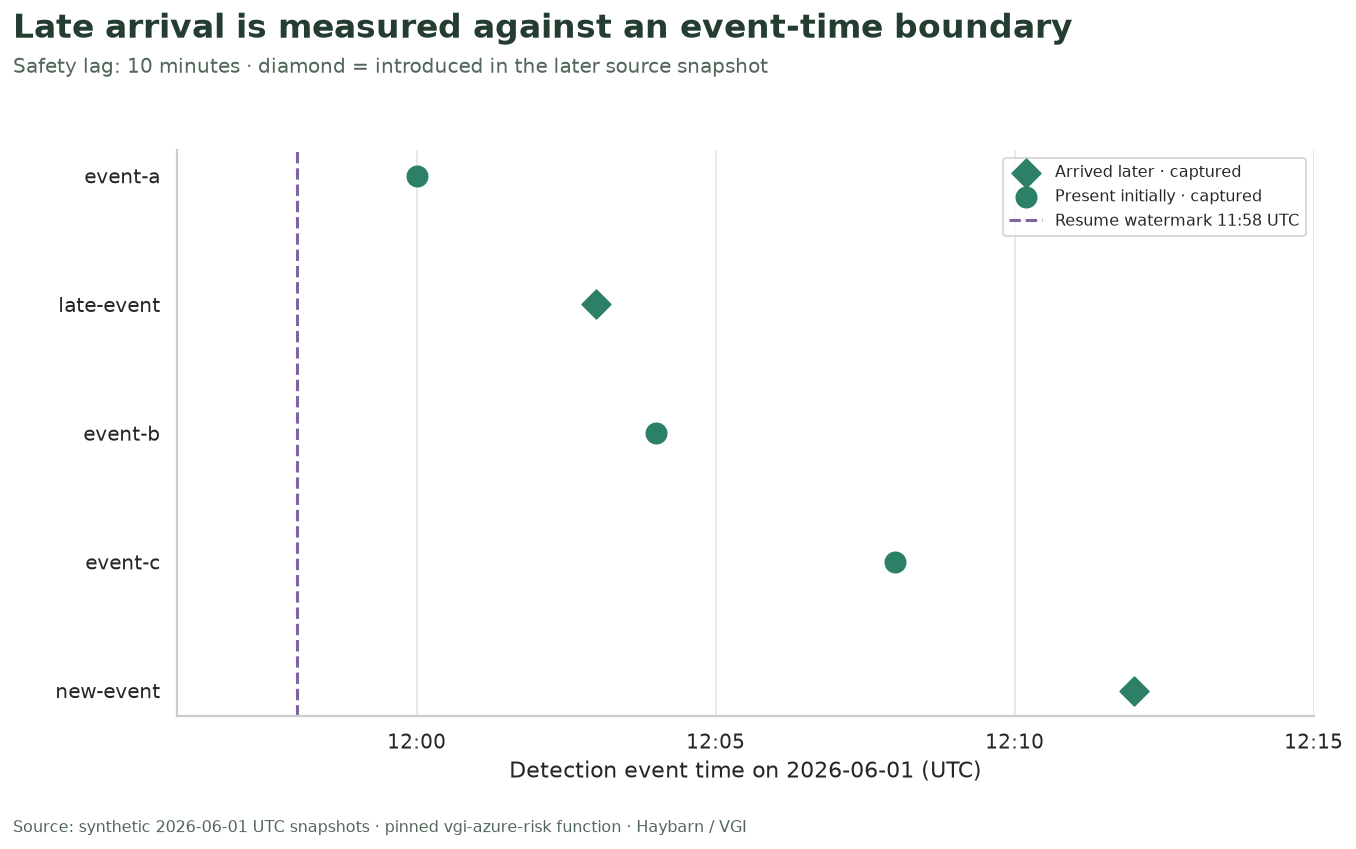

In [13]:
fig, ax = plt.subplots(figsize=(11.5, 6.6))
for (origin, captured), rows in audit.groupby(["observed_when", "captured"]):
    marker = "o" if origin == "Present initially" else "D"
    color = "#2b8067" if captured else "#c47548"
    label = f"{origin} · {'captured' if captured else 'missed'}"
    ax.scatter(rows.event_time, rows.index, s=125, marker=marker, color=color, label=label, zorder=3)
cursor_time = pd.Timestamp(c.watermark_time)
ax.axvline(
    cursor_time, color="#8064a2", linewidth=1.7, linestyle="--", label=f"Resume watermark {cursor_time:%H:%M} UTC"
)
ax.set_yticks(audit.index, audit.id)
ax.invert_yaxis()
ax.set_xlim(
    min(audit.event_time.min(), cursor_time) - timedelta(minutes=2), audit.event_time.max() + timedelta(minutes=3)
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=UTC))
ax.set_xlabel("Detection event time on 2026-06-01 (UTC)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", fontsize=9)
finish(
    fig,
    "Late arrival is measured against an event-time boundary",
    f"Safety lag: {SAFETY_LAG_MINUTES} {lag_unit} · diamond = introduced in the later source snapshot",
    f"timeline-lag-{SAFETY_LAG_MINUTES}.png",
)

In [14]:
%%sql counts <<
SELECT
    (SELECT count(*) FROM first_scan WHERE _row_kind IS NULL) AS initial_events,
    (SELECT count(*) FROM next_scan WHERE _row_kind IS NULL) AS incremental_rows,
    (SELECT count(*) FROM appended) AS appended_rows,
    (SELECT count(*) FROM stored_events) AS stored_events,
    (SELECT count(*) FROM reference_events) AS reference_events,
    (SELECT count(*) FROM reference_events r
        LEFT JOIN stored_events s ON r.id = s.id WHERE s.id IS NULL) AS missed_events;

In [15]:
a = counts.iloc[0]
repeats = int(a.appended_rows - a.stored_events)
repeat_label = "repeat" if repeats == 1 else "repeats"
id_label = "ID" if repeats == 1 else "IDs"
event_label = "event" if a.missed_events == 1 else "events"
prose(
    f"The incremental scan returns **{int(a.incremental_rows)} data rows**. "
    f"Appending both scans gives **{int(a.appended_rows)} observations**, including "
    f"**{repeats} repeated {id_label}**. Deduplication leaves **{int(a.stored_events)} events**; "
    f"the later reference contains **{int(a.reference_events)}**. "
    f"**Missed event IDs: {int(a.missed_events)}.**"
)

The incremental scan returns **5 data rows**. Appending both scans gives **8 observations**, including **3 repeated IDs**. Deduplication leaves **5 events**; the later reference contains **5**. **Missed event IDs: 0.**

## Keep repeated observations separate from unique events

The first bar decomposes the actual appended rows into unique event IDs and extra observations. The second is the deduplicated store. The third is the full later source. A gap between the latter two is a capture gap, even when the event-ID uniqueness check passes.

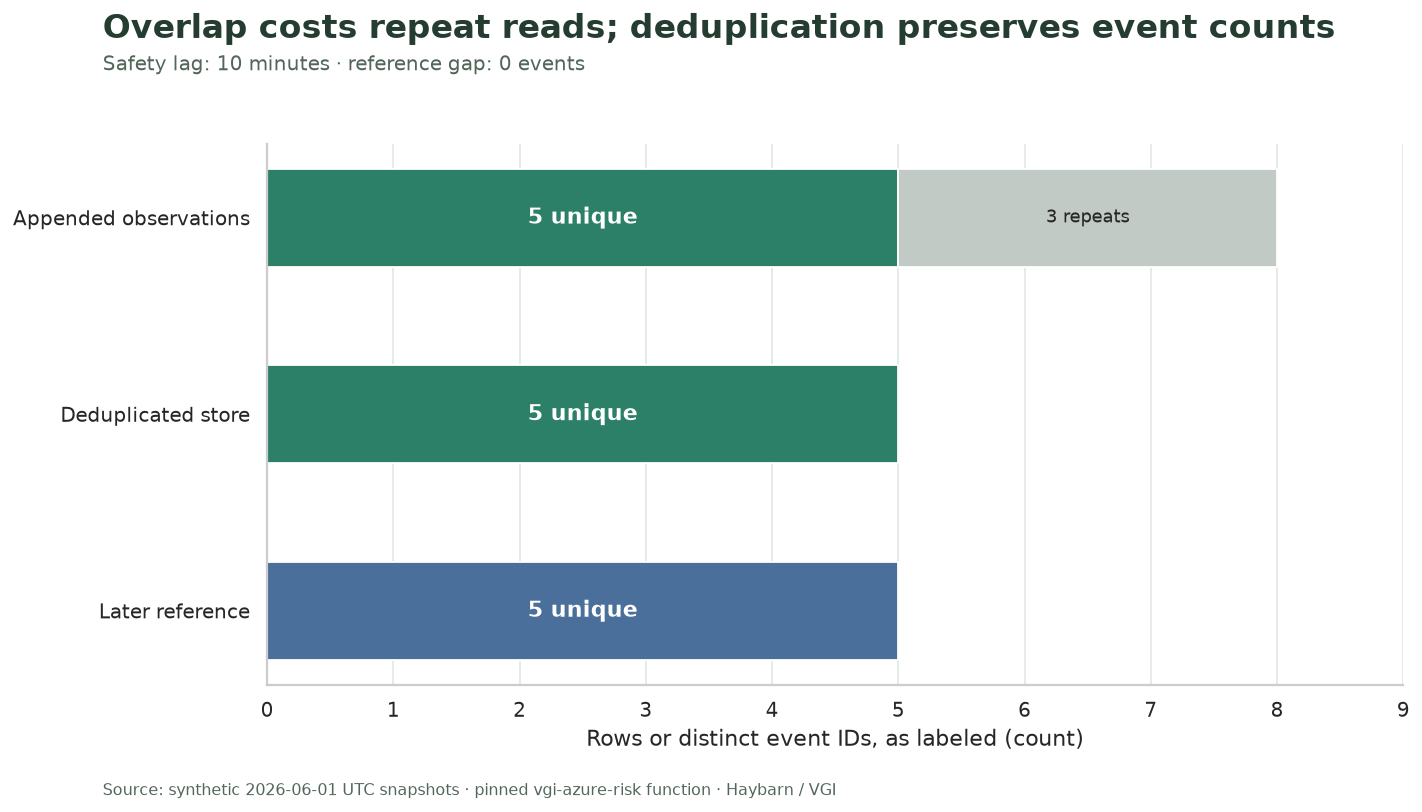

In [16]:
fig, ax = plt.subplots(figsize=(11.5, 6.3))
values = [int(a.stored_events), int(a.stored_events), int(a.reference_events)]
labels = ["Appended observations", "Deduplicated store", "Later reference"]
ax.barh([0, 1, 2], values, color=["#2b8067", "#2b8067", "#4a6f9b"], height=0.5)
if repeats:
    ax.barh(0, repeats, left=int(a.stored_events), color="#c1cac5", height=0.5)
    ax.text(int(a.stored_events) + repeats / 2, 0, f"{repeats} {repeat_label}", ha="center", va="center", fontsize=10)
for i, value in enumerate(values):
    ax.text(value / 2, i, f"{value} unique", ha="center", va="center", color="white", weight="bold")
ax.set_yticks([0, 1, 2], labels)
ax.invert_yaxis()
ax.set_xlim(0, max(int(a.appended_rows), int(a.reference_events)) + 1)
ax.set_xticks(range(max(int(a.appended_rows), int(a.reference_events)) + 2))
ax.set_xlabel("Rows or distinct event IDs, as labeled (count)")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Overlap costs repeat reads; deduplication preserves event counts",
    f"Safety lag: {SAFETY_LAG_MINUTES} {lag_unit} · reference gap: {int(a.missed_events)} {event_label}",
    f"counts-lag-{SAFETY_LAG_MINUTES}.png",
)

## Check the accounting without assuming full capture

A zero-lag experiment is expected to miss the late event, so the checks do not require zero misses. They require unique stored IDs, a correct captured/missed partition of the reference, valid event times and a single cursor marker for each scan.

In [17]:
%%sql checks <<
SELECT
    (SELECT count(*) - count(DISTINCT id) FROM stored_events) AS duplicate_ids,
    (SELECT count(*) FROM stored_events WHERE id IS NULL OR detected_date_time IS NULL) AS missing_keys_or_times,
    (SELECT count(*) FROM stored_events s
        LEFT JOIN reference_events r ON s.id = r.id WHERE r.id IS NULL) AS unexpected_ids,
    (SELECT count(*) FROM first_scan WHERE _row_kind = 'marker') AS first_markers,
    (SELECT count(*) FROM next_scan WHERE _row_kind = 'marker') AS next_markers,
    (SELECT count(*) FROM reference_scan WHERE _row_kind = 'marker') AS reference_markers;

In [18]:
display(checks)
k = checks.iloc[0]
assert k.duplicate_ids == 0 and k.missing_keys_or_times == 0 and k.unexpected_ids == 0
assert k.first_markers == 1 and k.next_markers == 1 and k.reference_markers == 1
assert a.stored_events + a.missed_events == a.reference_events
assert gap == SAFETY_LAG_MINUTES
prose(
    "Identity, availability and count relationships hold. A bounded overlap only protects arrivals "
    "inside that window; it cannot guarantee capture of arbitrarily old arrivals. This analysis checks "
    "event capture, not a user's current risk verdict, which requires reconciliation with current risk-state data."
)

,duplicate_ids,missing_keys_or_times,unexpected_ids,first_markers,next_markers,reference_markers
0,0,0,0,1,1,1


Identity, availability and count relationships hold. A bounded overlap only protects arrivals inside that window; it cannot guarantee capture of arbitrarily old arrivals. This analysis checks event capture, not a user's current risk verdict, which requires reconciliation with current risk-state data.

## Experiment: remove the safety lag

Change **`SAFETY_LAG_MINUTES = 10` to `0`**, restart and run all. Predict that the cursor moves to the newest first-scan event time. The inclusive boundary should still repeat that event, while the late arrival falls before the cursor. Compare the timeline’s missed marker, repeated-row count and reference gap.

The source snapshots and injected clocks are identical across runs, so the difference isolates this fixture’s cursor policy. It does not estimate a production lateness distribution. Reset **`SAFETY_LAG_MINUTES = 10`** for the default. Use the runner’s separate output directory to retain both executions.

In [19]:
connection.close()
fixture_secret_directory.cleanup()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)